# E-COMMERCE PROFIT PREDICTION

Algorithms: Linear Regression and Random Forest Regressor
#
Dataset: Cleaned_master_Olist_Data.csv

# Importing Packages

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

# 1. LOAD DATASET

In [3]:
FILE_PATH = r"C:\Users\Asus\OneDrive\Desktop\Falguni\Main data which we have to work\Cleaned_master_Olist_Data.csv"

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(
        f"Dataset not found: {FILE_PATH}\n"
        "Place the CSV file in the same folder as this script."
    )

df = pd.read_csv(FILE_PATH)

print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst five rows:")
df.head()

DATASET INFORMATION
Dataset shape: (114835, 44)

Columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'product_cost', 'discount', 'return_loss', 'profit', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'product_category_name_english', 'seller_zip_code_prefix', 'seller_city', 'seller_state', 'payment_sequential', 'payment_type', 'payment_installments', 'payment_value', 'review_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

First five rows:


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,...,payment_sequential,payment_type,payment_installments,payment_value,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,1.0,credit_card,1.0,18.12,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,3.0,voucher,1.0,2.00,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,...,2.0,voucher,1.0,18.59,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,...,1.0,boleto,1.0,141.46,8d5266042046a06655c8db133d120ba5,4.0,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,...,1.0,credit_card,3.0,179.12,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58


# 2. CHECK REQUIRED COLUMNS

In [4]:
required_columns = [
    "order_id",
    "order_item_id",
    "product_id",
    "seller_id",
    "order_purchase_timestamp",
    "profit",
    "price"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}"
    )

# 3. REMOVE DUPLICATE PRODUCT-ITEM RECORDS

The original dataset may repeat an order item because 
#
payment information can have multiple records per order.
#
Keep one row per order item for item-level profit prediction.

In [5]:
item_key = [
    "order_id",
    "order_item_id",
    "product_id",
    "seller_id"
]

before = len(df)

df = df.drop_duplicates(
    subset=item_key,
    keep="first"
).copy()

print("\nRows before deduplication:", before)
print("Rows after deduplication:", len(df))


Rows before deduplication: 114835
Rows after deduplication: 109343


# 4. CONVERT DATA TYPES

In [6]:
df["order_purchase_timestamp"] = pd.to_datetime(
    df["order_purchase_timestamp"],
    errors="coerce"
)

# Convert numeric columns safely.

numeric_columns = [
    "profit",
    "price",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

# Target and purchase timestamp are required.

df = df.dropna(
    subset=["profit", "order_purchase_timestamp"]
).copy()

# Exclude infinite target values.

df = df[
    np.isfinite(df["profit"])
].copy()

# 5. FEATURE ENGINEERING

In [7]:
# Extract information available from the purchase timestamp.

df["purchase_month"] = (
    df["order_purchase_timestamp"].dt.month
)

df["purchase_day_of_week"] = (
    df["order_purchase_timestamp"].dt.dayofweek
)

df["purchase_hour"] = (
    df["order_purchase_timestamp"].dt.hour
)


# 6. DEFINE TARGET AND FEATURES

In [8]:
TARGET = "profit"

# These features describe the product and purchase context.
# Direct profit components are deliberately excluded.

numeric_features = [
    "price",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
    "product_name_lenght",
    "product_description_lenght",
    "product_photos_qty",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour"
]

categorical_features = [
    "product_category_name_english",
    "seller_state",
    "customer_state"
]

# Keep only features present in the uploaded dataset.

numeric_features = [
    col for col in numeric_features
    if col in df.columns
]

categorical_features = [
    col for col in categorical_features
    if col in df.columns
]

feature_columns = (
    numeric_features + categorical_features
)

if not feature_columns:
    raise ValueError("No usable feature columns found.")

# Drop rows where every selected feature is missing.

df = df.dropna(
    subset=feature_columns,
    how="all"
).copy()

X = df[feature_columns].copy()
y = df[TARGET].copy()

# Make categorical values consistent.

for col in categorical_features:
    X[col] = X[col].apply(
        lambda value: (
            str(value)
            if pd.notna(value)
            else np.nan
        )
    )

print("\nTarget variable:", TARGET)
print("Selected features:", feature_columns)
print("Number of records:", len(df))

print("\nProfit summary:")
print(y.describe())


Target variable: profit
Selected features: ['price', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'purchase_month', 'purchase_day_of_week', 'purchase_hour', 'product_category_name_english', 'seller_state', 'customer_state']
Number of records: 109343

Profit summary:
count    109343.000000
mean          8.869536
std          67.419385
min       -4706.070000
25%          -5.750000
50%           3.210000
75%          18.840000
max        2355.080000
Name: profit, dtype: float64


# 7. TRAIN-TEST SPLIT

In [9]:
# Sort by purchase date so the latest records form the test set.
# This provides a more realistic test than a random row split.

df = df.sort_values(
    "order_purchase_timestamp"
).reset_index(drop=True)

X = df[feature_columns].copy()
y = df[TARGET].copy()

for col in categorical_features:
    X[col] = X[col].apply(
        lambda value: (
            str(value)
            if pd.notna(value)
            else np.nan
        )
    )

split_index = int(len(df) * 0.80)

if split_index < 2 or len(df) - split_index < 2:
    raise ValueError(
        "Not enough records for train-test splitting."
    )

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print(
    "Training period:",
    df["order_purchase_timestamp"].iloc[0],
    "to",
    df["order_purchase_timestamp"].iloc[split_index - 1]
)

print(
    "Testing period:",
    df["order_purchase_timestamp"].iloc[split_index],
    "to",
    df["order_purchase_timestamp"].iloc[-1]
)


Training records: 87474
Testing records: 21869
Training period: 2016-10-03 09:44:50 to 2018-05-25 23:56:57
Testing period: 2018-05-26 00:14:44 to 2018-08-29 15:00:37


# 8. DATA PREPROCESSING

In [10]:
# Numeric columns:
# 1. Fill missing values using the median.
# 2. Scale numeric features for Linear Regression.

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Categorical columns:
# 1. Fill missing values using the most frequent value.
# 2. Convert categories into numeric indicator columns.

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            numeric_features
        ),
        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ],
    remainder="drop"
)


# 9. DEFINE MACHINE LEARNING MODELS

In [11]:
# Model 1: Linear Regression

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

# Model 2: Random Forest Regressor

random_forest_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=20,
                min_samples_split=5,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)


# 10. TRAIN AND EVALUATE MODELS

In [12]:
models = {
    "Linear Regression": linear_model,
    "Random Forest": random_forest_model
}

results = {}
predictions = {}

for model_name, model in models.items():

    print("\n" + "=" * 60)
    print("TRAINING:", model_name)
    print("=" * 60)

    # Train the model.

    model.fit(X_train, y_train)

    # Predict profit on unseen test records.

    y_pred = model.predict(X_test)

    # Calculate evaluation metrics.

    mae = mean_absolute_error(
        y_test,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            y_pred
        )
    )

    r2 = r2_score(
        y_test,
        y_pred
    )

    results[model_name] = {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

    predictions[model_name] = y_pred

    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R2   : {r2:.4f}")


TRAINING: Linear Regression
MAE  : 17.3448
RMSE : 55.4006
R2   : 0.3454

TRAINING: Random Forest
MAE  : 17.8984
RMSE : 57.1157
R2   : 0.3043


# 11. COMPARE MODELS

In [13]:
results_df = pd.DataFrame(
    results
).T

print("\n" + "=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

print(results_df.round(4))

results_df.to_csv(
    "model_comparison.csv"
)

# Lower MAE and RMSE are better.
# Higher R2 is generally better.

best_model_name = results_df["MAE"].idxmin()

print("\nBest model by test MAE:", best_model_name)


MODEL COMPARISON
                       MAE     RMSE      R2
Linear Regression  17.3448  55.4006  0.3454
Random Forest      17.8984  57.1157  0.3043

Best model by test MAE: Linear Regression


MODEL COMPARISON

<Figure size 900x600 with 0 Axes>

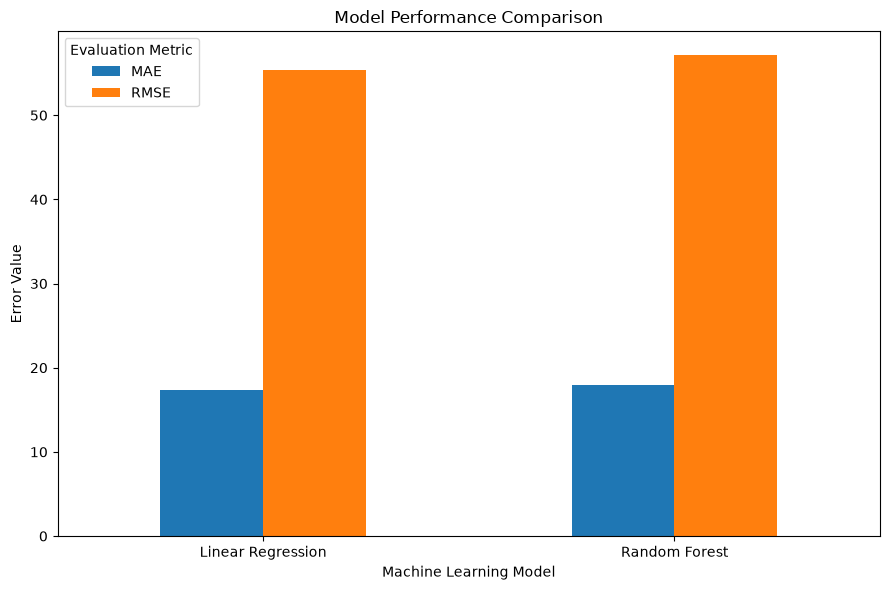

In [26]:
plt.figure(figsize=(9, 6))

results_df[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Error Value")
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.tight_layout()

plt.savefig(
    r"C:\Users\Asus\OneDrive\Desktop\Falguni\graphs/model_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 12. ACTUAL VS PREDICTED PROFIT

In [14]:
best_model = models[best_model_name]

best_predictions = predictions[best_model_name]

comparison_df = pd.DataFrame({
    "Actual_Profit": y_test.to_numpy(),
    "Predicted_Profit": best_predictions
})

comparison_df["Prediction_Error"] = (
    comparison_df["Actual_Profit"]
    - comparison_df["Predicted_Profit"]
)

print("\nActual vs Predicted Profit:")
print(comparison_df.head(15).round(2))

comparison_df.to_csv(
    "actual_vs_predicted.csv",
    index=False
)



Actual vs Predicted Profit:
    Actual_Profit  Predicted_Profit  Prediction_Error
0            1.79              1.87             -0.08
1           19.65             13.52              6.13
2            9.70              8.03              1.67
3           16.27             -4.62             20.89
4           58.70             56.59              2.11
5           19.71            -16.41             36.12
6           13.72              1.92             11.80
7            7.56              1.92              5.64
8          -90.89              1.92            -92.81
9          254.58            204.90             49.68
10          17.76              9.19              8.57
11          23.22             -4.66             27.88
12          18.55             -6.44             24.99
13           7.93              7.96             -0.03
14          15.98              6.90              9.08


# 13. VISUALIZE ACTUAL VS PREDICTED VALUES

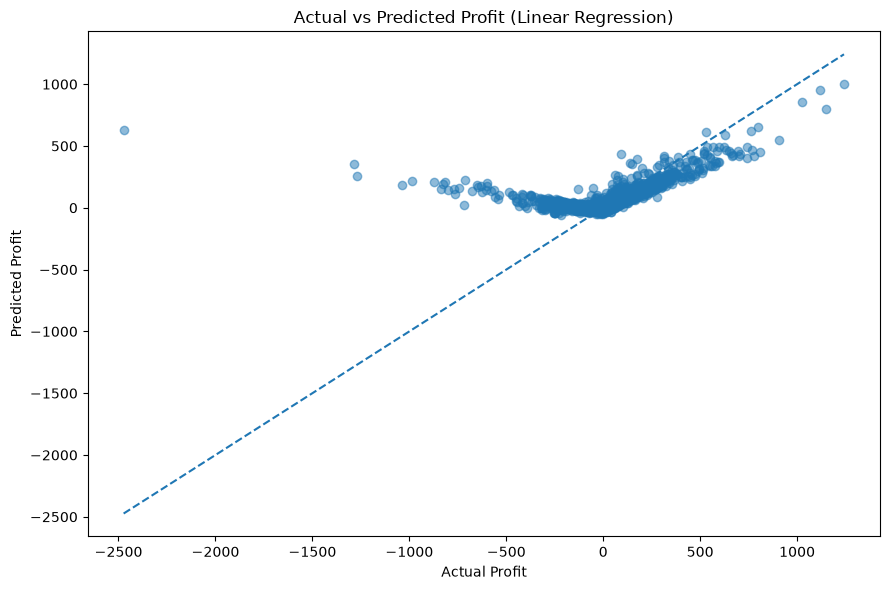

In [27]:
plt.figure(figsize=(9, 6))

plt.scatter(
    comparison_df["Actual_Profit"],
    comparison_df["Predicted_Profit"],
    alpha=0.5
)

# Reference line: perfect predictions lie on this line.

min_value = min(
    comparison_df["Actual_Profit"].min(),
    comparison_df["Predicted_Profit"].min()
)

max_value = max(
    comparison_df["Actual_Profit"].max(),
    comparison_df["Predicted_Profit"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")

plt.title(
    f"Actual vs Predicted Profit ({best_model_name})"
)

plt.tight_layout()

plt.savefig(
    r"C:\Users\Asus\OneDrive\Desktop\Falguni\graphs\actual_vs_predicted.png",
    dpi=300
)

plt.show()

# 14. SAVE TRAINED MODEL

In [16]:
MODEL_PATH = r"C:\Users\Asus\OneDrive\Desktop\Falguni\Model\profit_prediction_model.pkl"

joblib.dump(
    best_model,
    MODEL_PATH
)

print("\nModel saved successfully:", MODEL_PATH)


Model saved successfully: C:\Users\Asus\OneDrive\Desktop\Falguni\Model\profit_prediction_model.pkl


# 15. PREDICT PROFIT FOR A NEW EXAMPLE

In [17]:
# This is an illustrative example.
# The category, price, dimensions and locations are example inputs.
# They are not actual values for a specific new order.

new_order = {
    "price": 190.0,
    "product_weight_g": 1200.0,
    "product_length_cm": 30.0,
    "product_height_cm": 15.0,
    "product_width_cm": 20.0,
    "product_name_lenght": 40.0,
    "product_description_lenght": 300.0,
    "product_photos_qty": 3.0,
    "purchase_month": 10,
    "purchase_day_of_week": 2,
    "purchase_hour": 14,
    "product_category_name_english": "housewares",
    "seller_state": "SP",
    "customer_state": "SP"
}

# Construct a DataFrame with exactly the model's features.

new_order_df = pd.DataFrame(
    [new_order]
).reindex(
    columns=feature_columns
)

# Load the saved model and predict.

loaded_model = joblib.load(
    MODEL_PATH
)

predicted_profit = loaded_model.predict(
    new_order_df
)[0]

print("\n" + "=" * 60)
print("NEW ORDER PROFIT PREDICTION")
print("=" * 60)

print("Input price:", new_order["price"])

print(
    f"Estimated profit: {predicted_profit:.2f}"
)

print(
    "Note: This is an ML estimate, not guaranteed profit."
)

print("\nPROJECT COMPLETED SUCCESSFULLY!")


NEW ORDER PROFIT PREDICTION
Input price: 190.0
Estimated profit: 30.51
Note: This is an ML estimate, not guaranteed profit.

PROJECT COMPLETED SUCCESSFULLY!
